# 03 · Hyper-parameter Search
## DSA 4050-XA CAT 2: Image Classification with PyTorch

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Lecturer** | Dr. Alex Wambua |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `03_hyperparameter_search.ipynb` |
| **CAT requirement** | 3) appropriate algorithm for hyper-parameter selection |

### Objective
Replace the from-scratch baseline (81.1%) with **transfer learning** and choose its settings with a principled search instead of guesswork:
1. **Backbone screening:** fine-tune three ImageNet-pretrained architectures with identical default settings and keep the best.
2. **Bayesian hyper-parameter optimisation with Optuna:** the **TPE** (Tree-structured Parzen Estimator) algorithm proposes settings, and a **median pruner** stops unpromising trials early.

### Inputs
- Images, `train_folds.csv` (notebook 01)

### Outputs
| File | Purpose |
|---|---|
| `data/processed/best_params.json` | Best backbone + hyper-parameters, used by notebook 04 |
| `models/optuna/cat2_study.db` | The full Optuna study (every trial), resumable |
| `outputs/tables/03_*.csv`, `outputs/figures/03_*.png` | Screening results, all trials, search plots |
| Rows in `experiments.csv` | Validation accuracy of each screened backbone and of the best trial |

**Runtime (T4):** ~15 min screening + 45 min search (time limit) ≈ **1 hour**. Expect roughly 10–15 trials in 45 min (pruned trials are cheap). The study is saved to Drive after every trial: if Colab disconnects, or you want more trials, just re-run and it **continues where it stopped** (finished backbones are skipped too).

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/cat2-image-classification/src")

import importlib
import cat2_utils as cu
importlib.reload(cu)
cu.set_seed()

NOTEBOOK = "03_hyperparameter_search"
PATHS = cu.PATHS
print("Project root:", cu.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/cat2-image-classification


In [2]:
# timm and optuna are not pre-installed in every Colab session
!pip install -q timm optuna

In [3]:
import os, json, time, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, timm, optuna
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

DATA_SOURCE = "/content/drive/MyDrive/Advanced ML"      # the lecturer's shared folder (shortcut)
DATA_DIR = Path(cu.restore_data(DATA_SOURCE))
folds = pd.read_csv(os.path.join(PATHS["processed"], "train_folds.csv"))
X = cu.load_images(folds["id"], DATA_DIR / "train")
print(X.shape, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Source folder: /content/drive/MyDrive/Advanced ML
Unzipped 50,000 images to /content/cat2_data/train
(4000, 32, 32, 3) | GPU: Tesla T4


## 1 · Search set-up
All search runs use the **same split**: train on folds 1–4 (3,200 images), validate on **fold 0** (800 images), exactly as the baseline, so results are comparable. The final model (notebook 04) is checked on all five folds.

**Image size:** the 32×32 images are **upscaled to 224×224**, the resolution the pretrained networks were trained at; their filters are tuned to objects of that size.

In [4]:
IMG_SIZE = 224
BATCH = 64
VAL_FOLD = 0
PRETRAINED = True
tr = (folds["fold"] != VAL_FOLD).to_numpy()
va = (folds["fold"] == VAL_FOLD).to_numpy()


def loaders(randaug_magnitude=9, erase_prob=0.25, img_size=IMG_SIZE, batch=BATCH):
    """Train/validation DataLoaders built from the custom Dataset class (notebook 01)."""
    train_ds = cu.CIFARCSVDataset(folds[tr], images=X[tr],
                                  transform=cu.build_transforms(True, img_size, randaug_magnitude, erase_prob))
    val_ds = cu.CIFARCSVDataset(folds[va], images=X[va], transform=cu.build_transforms(False, img_size))
    return cu.make_loader(train_ds, batch, shuffle=True), cu.make_loader(val_ds, 128, shuffle=False)


def make_model(backbone, drop_path_rate=0.1):
    """ImageNet-pretrained backbone from timm with a new 10-class output layer."""
    kwargs = {"drop_path_rate": drop_path_rate} if "resnet" not in backbone else {}
    return timm.create_model(backbone, pretrained=PRETRAINED, num_classes=10, **kwargs)

## 2 · Backbone screening
Three strong pretrained architectures of different families, each fine-tuned for **8 epochs** with the **same** default settings (AdamW, lr 1e-4, weight decay 0.05, label smoothing 0.1, RandAugment 9):

| Backbone | Family | Pretraining | Size |
|---|---|---|---|
| `resnet50.a1_in1k` | Residual CNN (2015, modern training recipe) | ImageNet-1k | 25.6M |
| `convnext_tiny.fb_in22k_ft_in1k` | ConvNeXt, a modernised CNN (2022) | ImageNet-22k (14M images) → 1k | 28.6M |
| `vit_small_patch16_224.augreg_in21k_ft_in1k` | Vision Transformer (self-attention) | ImageNet-21k → 1k | 22.1M |

The winner is used for the hyper-parameter search. Screening backbones separately keeps the search focused: one categorical choice inside the search would need many more trials.

In [5]:
BACKBONES = ["resnet50.a1_in1k", "convnext_tiny.fb_in22k_ft_in1k", "vit_small_patch16_224.augreg_in21k_ft_in1k"]
SCREEN_EPOCHS = 8
screen_file = os.path.join(PATHS["tables"], "03_backbone_screening.csv")
screen = pd.read_csv(screen_file) if os.path.exists(screen_file) else pd.DataFrame(columns=["backbone"])

for bb in BACKBONES:
    if bb in set(screen["backbone"]):
        print(f"{bb}: already screened, skipping"); continue
    cu.set_seed()
    tl, vl = loaders()
    model = make_model(bb)
    t0 = time.time()
    res = cu.train_model(model, tl, vl, epochs=SCREEN_EPOCHS, lr=1e-4, weight_decay=0.05,
                         label_smoothing=0.1, warmup_epochs=1, verbose=False)
    row = {"backbone": bb, "val_acc": res["best_val_acc"], "best_epoch": res["best_epoch"],
           "params_millions": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
           "minutes": round((time.time() - t0) / 60, 1)}
    print(f"{bb:<45} val acc {row['val_acc']:.4f}  ({row['minutes']} min)")
    screen = pd.concat([screen, pd.DataFrame([row])], ignore_index=True)
    screen.to_csv(screen_file, index=False)                              # save after every backbone
    cu.log_experiment(f"screen_{bb.split('.')[0]}", {"val_acc_fold0": round(row["val_acc"], 4),
                      "train_minutes": row["minutes"], "params_millions": row["params_millions"], "img_size": IMG_SIZE},
                      NOTEBOOK, params={"epochs": SCREEN_EPOCHS, "lr": 1e-4, "wd": 0.05, "randaug": 9})
    del model; torch.cuda.empty_cache()

screen = screen.sort_values("val_acc", ascending=False).reset_index(drop=True)
cu.save_table(screen, "03_backbone_screening", NOTEBOOK, caption="Validation accuracy of three pretrained backbones with identical default settings.")
BEST_BACKBONE = screen.loc[0, "backbone"]
cu.log_result("best_backbone", BEST_BACKBONE, NOTEBOOK)
screen

Random seed set to 42


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50.a1_in1k                              val acc 0.8600  (2.1 min)
Experiment logged: screen_resnet50 -> {'val_acc_fold0': 0.86, 'train_minutes': 2.1, 'params_millions': 23.5, 'img_size': 224}
Random seed set to 42


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

/content/drive/MyDrive/DSA4050/cat2-image-classification/src/cat2_utils.py:401: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


vit_small_patch16_224.augreg_in21k_ft_in1k    val acc 0.9637  (1.8 min)
Experiment logged: screen_vit_small_patch16_224 -> {'val_acc_fold0': 0.9637, 'train_minutes': 1.8, 'params_millions': 21.7, 'img_size': 224}
Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/03_backbone_screening.csv
Result logged: best_backbone = vit_small_patch16_224.augreg_in21k_ft_in1k


,backbone,val_acc,best_epoch,params_millions,minutes
0,vit_small_patch16_224.augreg_in21k_ft_in1k,0.96375,6.0,21.7,1.8
1,convnext_tiny.fb_in22k_ft_in1k,0.96250,8.0,27.8,2.5
2,resnet50.a1_in1k,0.86000,7.0,23.5,2.1


Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/03_backbone_screening.png


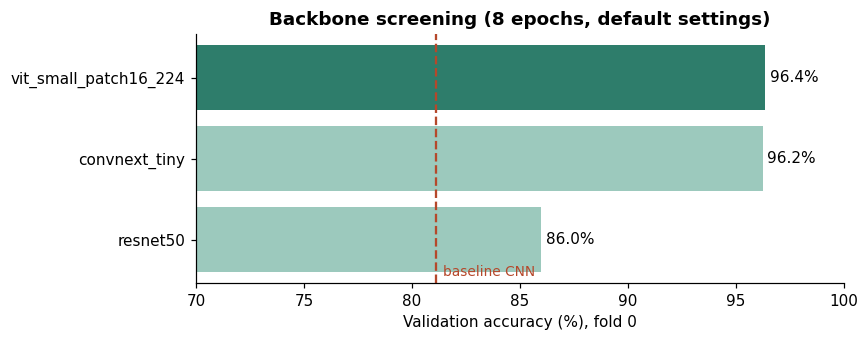

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = [b.split(".")[0] for b in screen["backbone"]][::-1]
bars = ax.barh(names, screen["val_acc"][::-1] * 100, color=["#9CC9BD"] * (len(screen) - 1) + ["#2E7D6B"])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in screen["val_acc"][::-1] * 100], padding=3)
ax.axvline(cu.load_results().get("baseline_val_acc", {}).get("value", 0.811) * 100, color="#B5482B", ls="--")
ax.text(cu.load_results().get("baseline_val_acc", {}).get("value", 0.811) * 100 + 0.3, -0.45, "baseline CNN", color="#B5482B", fontsize=9)
ax.set_xlim(70, 100); ax.set_xlabel("Validation accuracy (%), fold 0")
ax.set_title(f"Backbone screening ({SCREEN_EPOCHS} epochs, default settings)")
fig.tight_layout()
cu.save_figure(fig, "03_backbone_screening", NOTEBOOK, caption="Validation accuracy of each pretrained backbone vs the from-scratch baseline.")
plt.show()

**Interpretation:**
- **Transfer learning is a large step up.** Both modern pretrained backbones reached **≈96%** after only 8 epochs (about 2 minutes each), against **81.1%** for the CNN trained from scratch for 100 epochs. That cuts the error rate from ~19% to ~4%: the networks already know general visual features (edges, textures, object parts) from millions of ImageNet images, so 3,200 labelled examples are enough to adapt them.
- **ViT-Small (96.4%) and ConvNeXt-Tiny (96.3%) are effectively tied.** The difference is **one image out of 800**. ViT is kept because it scored (marginally) higher, is the smallest (21.7M parameters) and the fastest (1.8 min).
- **ResNet-50 is clearly behind (86.0%).** It was pretrained on ImageNet-1k only, while the other two were pretrained on the far larger ImageNet-21k/22k (≈14M images). The amount of pretraining data matters more than the architecture family here.
- The screening used one fixed set of default settings, so these numbers are a fair comparison but not each backbone's best. Tuning comes next.

## 3 · Bayesian hyper-parameter optimisation with Optuna (CAT requirement 3)
**Why not grid or random search?** A grid over 6 settings with only 4 values each is 4⁶ = 4,096 runs, far beyond our budget. Random search wastes trials in poor regions.

**Optuna's TPE sampler** (Tree-structured Parzen Estimator; Bergstra et al., 2011) is a **Bayesian optimisation** method:
1. The first trials are random.
2. It then splits past trials into "good" (top ~10–25%) and "bad", models the distribution of settings in each group, and proposes the settings most likely to come from the good group.
3. Each new result updates the model, so the search concentrates on promising regions.

**Median pruning:** after each epoch, a trial whose validation accuracy is below the **median** of earlier trials at the same epoch is stopped early. This frees time for more trials. The first 5 trials and the first 3 epochs of every trial are never pruned.

**Search space** (for the chosen backbone; 10 epochs per trial):

| Hyper-parameter | Range | Scale | Role |
|---|---|---|---|
| Learning rate | 2e-5 – 5e-4 | log | Step size for fine-tuning |
| Weight decay | 1e-3 – 0.2 | log | L2-style regularisation |
| Label smoothing | 0 – 0.2 | linear | Softer targets, less over-confidence |
| RandAugment magnitude | 0 – 15 | integer | Augmentation strength |
| Random-erasing probability | 0 – 0.5 | linear | Occlusion augmentation |
| Drop-path rate | 0 – 0.3 | linear | Randomly skips residual blocks (stochastic depth) |
| Warm-up epochs | 0 – 2 | integer | Gentle start for the new output layer |

**Objective:** maximise validation accuracy (fold 0). The study is stored in an SQLite database, so it can be resumed and analysed.

In [7]:
N_TRIALS = 20
TIMEOUT_MIN = 45
SEARCH_EPOCHS = 10
DB_DRIVE = os.path.join(PATHS["optuna"], "cat2_study.db")
DB_LOCAL = "/content/cat2_study.db" if os.path.isdir("/content") else os.path.join(PATHS["optuna"], "local_study.db")
if os.path.exists(DB_DRIVE) and not os.path.exists(DB_LOCAL):
    shutil.copy(DB_DRIVE, DB_LOCAL)        # resume a previous search (SQLite works best on local disk)


def objective(trial):
    params = {
        "lr": trial.suggest_float("lr", 2e-5, 5e-4, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-3, 0.2, log=True),
        "label_smoothing": trial.suggest_float("label_smoothing", 0.0, 0.2),
        "randaug_magnitude": trial.suggest_int("randaug_magnitude", 0, 15),
        "erase_prob": trial.suggest_float("erase_prob", 0.0, 0.5),
        "drop_path_rate": trial.suggest_float("drop_path_rate", 0.0, 0.3),
        "warmup_epochs": trial.suggest_int("warmup_epochs", 0, 2),
    }
    cu.set_seed()
    tl, vl = loaders(params["randaug_magnitude"], params["erase_prob"])
    model = make_model(BEST_BACKBONE, params["drop_path_rate"])

    def report(epoch, val_acc):                 # Optuna sees every epoch -> can prune
        trial.report(val_acc, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    try:
        res = cu.train_model(model, tl, vl, epochs=SEARCH_EPOCHS, lr=params["lr"],
                             weight_decay=params["weight_decay"], label_smoothing=params["label_smoothing"],
                             warmup_epochs=params["warmup_epochs"], epoch_callback=report, verbose=False)
    finally:
        del model; torch.cuda.empty_cache()
    trial.set_user_attr("best_epoch", res["best_epoch"])
    return res["best_val_acc"]


def backup(study, trial):                       # copy the study to Drive after every trial
    shutil.copy(DB_LOCAL, DB_DRIVE)
    state = trial.state.name.lower()
    val = f"{trial.value:.4f}" if trial.value is not None else "-"
    print(f"trial {trial.number:>2}  {state:<8} val_acc {val}  best so far {study.best_value:.4f}")


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    study_name=f"cat2_{BEST_BACKBONE.split('.')[0]}", storage=f"sqlite:///{DB_LOCAL}", load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=cu.SEED, n_startup_trials=6),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))

done = len([tr_ for tr_ in study.trials if tr_.state.is_finished()])
remaining = max(0, N_TRIALS - done)
print(f"{done} trials already finished; running up to {remaining} more (time limit {TIMEOUT_MIN} min)")
t0 = time.time()
if remaining:
    study.optimize(objective, n_trials=remaining, timeout=TIMEOUT_MIN * 60, callbacks=[backup], gc_after_trial=True)
print(f"Search time this session: {(time.time() - t0) / 60:.1f} min")

0 trials already finished; running up to 20 more (time limit 45 min)
Random seed set to 42


/content/drive/MyDrive/DSA4050/cat2-image-classification/src/cat2_utils.py:401: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


trial  0  complete val_acc 0.9738  best so far 0.9738
Random seed set to 42
trial  1  complete val_acc 0.9463  best so far 0.9738
Random seed set to 42
trial  2  complete val_acc 0.9700  best so far 0.9738
Random seed set to 42
trial  3  complete val_acc 0.9712  best so far 0.9738
Random seed set to 42
trial  4  complete val_acc 0.9475  best so far 0.9738
Random seed set to 42
trial  5  pruned   val_acc 0.9225  best so far 0.9738
Random seed set to 42
trial  6  pruned   val_acc 0.9637  best so far 0.9738
Random seed set to 42
trial  7  pruned   val_acc 0.9225  best so far 0.9738
Random seed set to 42
trial  8  pruned   val_acc 0.8975  best so far 0.9738
Random seed set to 42
trial  9  complete val_acc 0.9700  best so far 0.9738
Random seed set to 42
trial 10  pruned   val_acc 0.9625  best so far 0.9738
Random seed set to 42
trial 11  complete val_acc 0.9750  best so far 0.9750
Random seed set to 42
trial 12  pruned   val_acc 0.9350  best so far 0.9750
Random seed set to 42
trial 13  pr

## 4 · Search results

In [8]:
trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "duration"))
trials["duration_min"] = trials["duration"].dt.total_seconds() / 60
trials = trials.drop(columns="duration").rename(columns=lambda s: s.replace("params_", ""))
trials = trials.sort_values("value", ascending=False)
cu.save_table(trials.round(5), "03_optuna_trials", NOTEBOOK, caption="Every Optuna trial: settings, validation accuracy and status.")

n_complete = int((trials["state"] == "COMPLETE").sum()); n_pruned = int((trials["state"] == "PRUNED").sum())
best = study.best_trial
print(f"Trials: {len(trials)} ({n_complete} complete, {n_pruned} pruned)")
print(f"Best trial #{best.number}: val acc {best.value:.4f}")
for k, v in best.params.items():
    print(f"  {k:<18} {v:.5g}" if isinstance(v, float) else f"  {k:<18} {v}")
trials.head(10)

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/03_optuna_trials.csv
Trials: 20 (10 complete, 10 pruned)
Best trial #19: val acc 0.9812
  lr                 9.2285e-05
  weight_decay       0.093117
  label_smoothing    0.19615
  randaug_magnitude  8
  erase_prob         0.21249
  drop_path_rate     0.0014755
  warmup_epochs      0


,number,value,state,drop_path_rate,erase_prob,label_smoothing,lr,randaug_magnitude,warmup_epochs,weight_decay,duration_min
19,19,0.98125,COMPLETE,0.001476,0.212491,0.196151,0.000092,8,0,0.093117,2.192900
11,11,0.97500,COMPLETE,0.029208,0.018296,0.124226,0.000029,10,1,0.022640,2.146637
0,0,0.97375,COMPLETE,0.046798,0.078009,0.146399,0.000067,9,0,0.154036,2.305581
15,15,0.97375,COMPLETE,0.046349,0.003353,0.167724,0.000039,6,1,0.037637,2.195034
16,16,0.97375,COMPLETE,0.018526,0.034594,0.067675,0.000067,8,0,0.115593,2.204168
3,3,0.97125,COMPLETE,0.059902,0.392588,0.073272,0.000031,7,1,0.004701,2.209658
9,9,0.97000,COMPLETE,0.021741,0.106820,0.197446,0.000106,11,1,0.022655,2.192448
2,2,0.97000,COMPLETE,0.087369,0.215973,0.060848,0.000036,8,1,0.002643,2.208843
6,6,0.96375,PRUNED,0.139143,0.087606,0.108458,0.000100,5,0,0.125001,1.302065
10,10,0.96250,PRUNED,0.155425,0.313648,0.088622,0.000044,4,0,0.047963,1.082939


Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/03_param_importance.csv
Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/03_optuna_history_importance.png


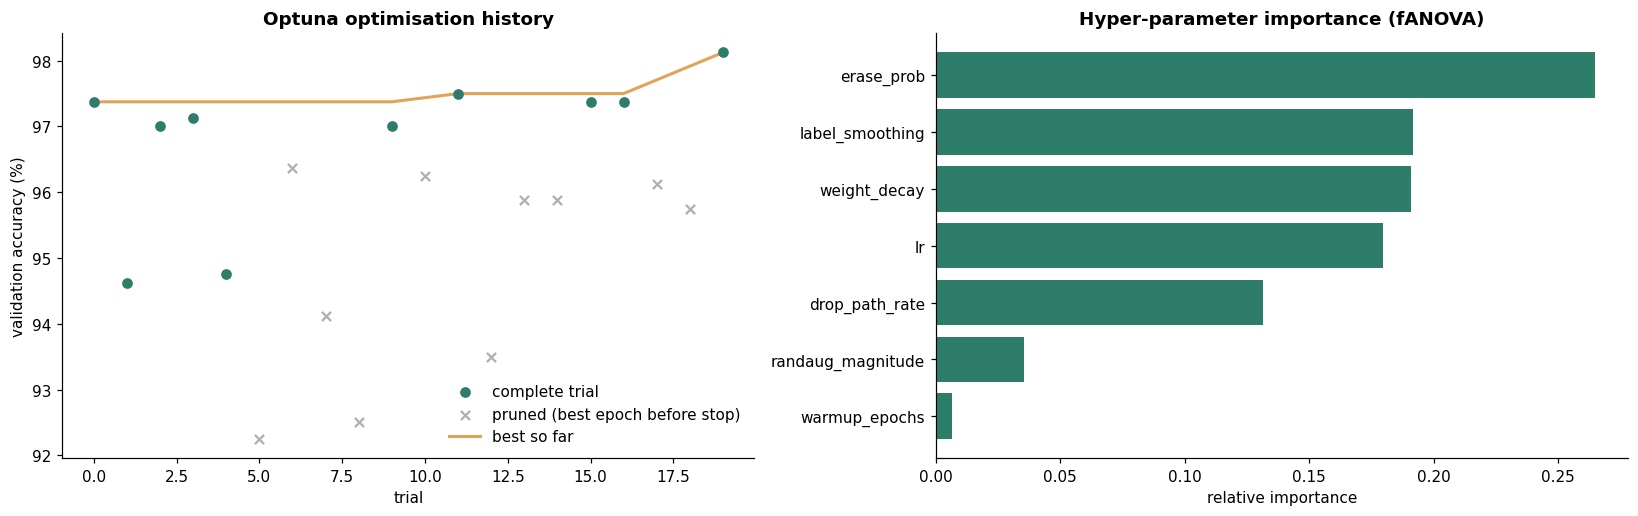

In [9]:
# Optimisation history (left) and hyper-parameter importance (right)
from optuna.visualization import matplotlib as ovm
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
complete = [t_ for t_ in study.trials if t_.state == optuna.trial.TrialState.COMPLETE]
xs = [t_.number for t_ in complete]; ys = [t_.value * 100 for t_ in complete]
pr = [t_ for t_ in study.trials if t_.state == optuna.trial.TrialState.PRUNED]
axes[0].scatter(xs, ys, color="#2E7D6B", label="complete trial", zorder=3)
axes[0].scatter([t_.number for t_ in pr], [max(t_.intermediate_values.values()) * 100 for t_ in pr],
                color="#B0B0B0", marker="x", label="pruned (best epoch before stop)", zorder=3)
axes[0].plot(xs, np.maximum.accumulate(ys), color="#E0A458", lw=2, label="best so far")
axes[0].set_xlabel("trial"); axes[0].set_ylabel("validation accuracy (%)"); axes[0].legend(frameon=False)
axes[0].set_title("Optuna optimisation history")
try:
    imp = optuna.importance.get_param_importances(study)
    axes[1].barh(list(imp.keys())[::-1], list(imp.values())[::-1], color="#2E7D6B")
    axes[1].set_xlabel("relative importance"); axes[1].set_title("Hyper-parameter importance (fANOVA)")
    cu.save_table(pd.DataFrame(imp.items(), columns=["hyperparameter", "importance"]).round(4),
                  "03_param_importance", NOTEBOOK, caption="Relative importance of each hyper-parameter (fANOVA).")
except Exception as e:
    axes[1].text(0.5, 0.5, f"importance needs more complete trials\n({e.__class__.__name__})", ha="center"); axes[1].axis("off")
fig.tight_layout()
cu.save_figure(fig, "03_optuna_history_importance", NOTEBOOK, caption="Optuna search progress and hyper-parameter importance.")
plt.show()

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/03_optuna_slices.png


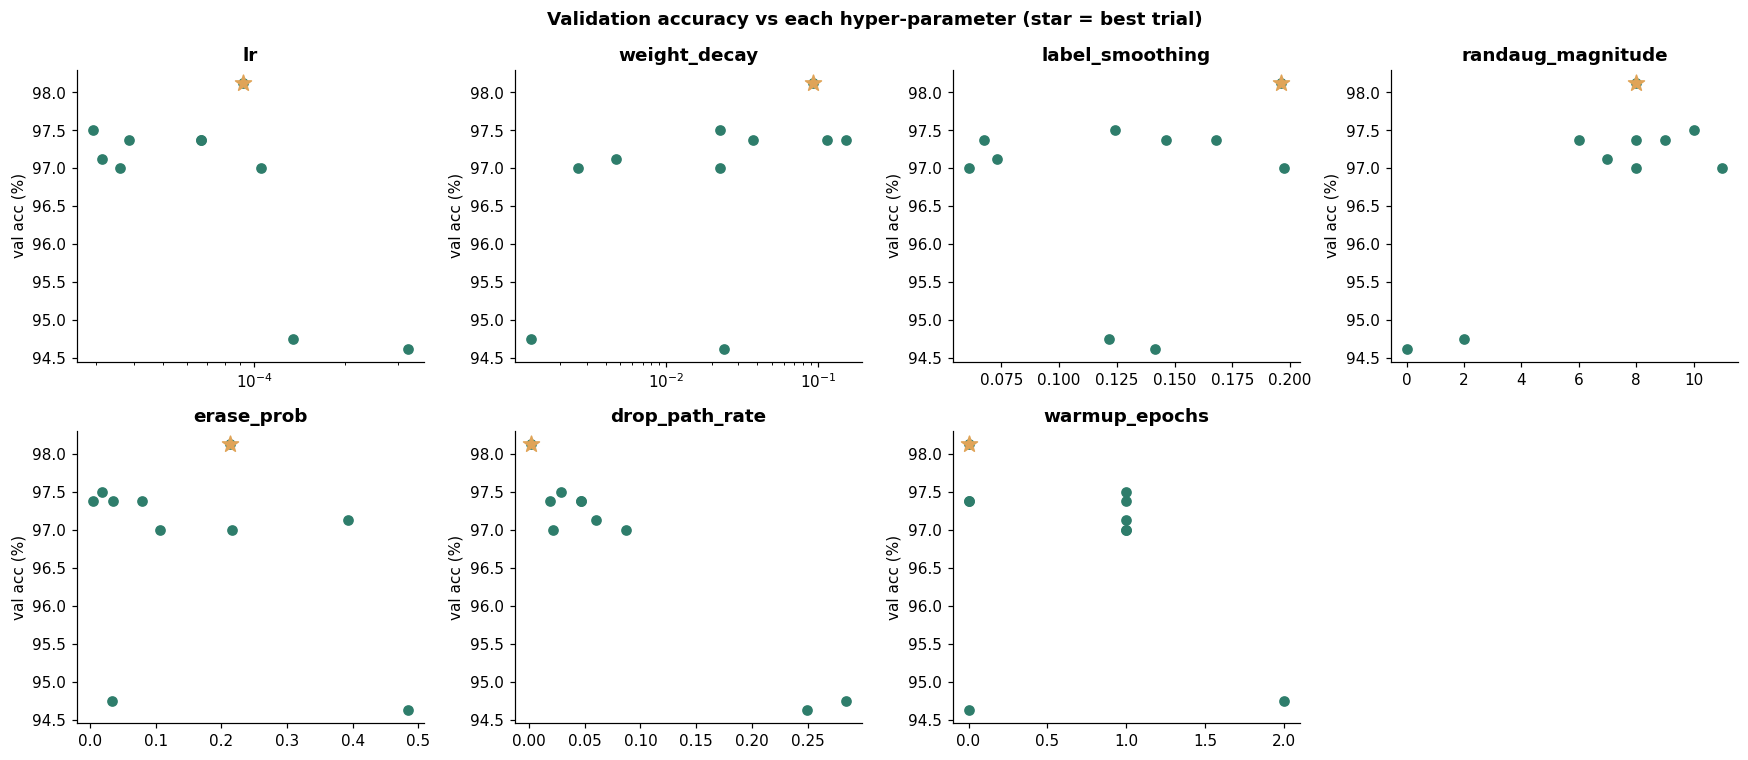

In [10]:
# Each hyper-parameter against validation accuracy (complete trials)
p_names = list(best.params.keys())
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
df_c = trials[trials["state"] == "COMPLETE"]
for ax, p in zip(axes.flat, p_names):
    ax.scatter(df_c[p], df_c["value"] * 100, color="#2E7D6B")
    ax.scatter([best.params[p]], [best.value * 100], color="#E0A458", s=120, marker="*", zorder=3)
    if p in ("lr", "weight_decay"):
        ax.set_xscale("log")
    ax.set_title(p); ax.set_ylabel("val acc (%)")
for ax in list(axes.flat)[len(p_names):]:
    ax.axis("off")
fig.suptitle("Validation accuracy vs each hyper-parameter (star = best trial)", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "03_optuna_slices", NOTEBOOK, caption="Validation accuracy against each hyper-parameter; the star marks the best trial.")
plt.show()

**Interpretation:**
- **Search outcome:** 20 trials in 34 minutes, **10 completed and 10 stopped early** by the median pruner. Pruning about halved the cost of bad trials (≈1.1–1.3 min instead of ≈2.2 min), which is what allowed all 20 trials to fit inside the time limit.
- **Best trial (#19): 98.1% validation accuracy**, up from 96.4% for ViT with default settings (+1.75 points). The validation **error fell from 3.6% to 1.9%**, nearly halved.
- **What the best settings look like:** learning rate ≈ 9e-5, fairly strong weight decay (0.09) and **strong label smoothing (0.20)**. It uses moderate RandAugment (8), random erasing on ~21% of images, essentially **no drop-path**, and **no warm-up**. Strong regularisation (weight decay plus label smoothing) helps, which makes sense with only 3,200 training images.
- **What hurt:** the two weakest completed trials (≈94.6%) combined **high drop-path (≈0.25–0.28) with little or no RandAugment (0–2)**. Very high learning rates (≥1.5e-4) also scored lower. RandAugment magnitudes of 6–11 were consistently good.
- **Importance plot (fANOVA):** erase probability, label smoothing, weight decay and learning rate matter most, and warm-up barely matters. With only 10 completed trials these importances are rough indications, not precise measurements.

**Caution, kept honest:** the best trial was *selected* on fold 0, so 98.1% is slightly optimistic: picking the maximum of 20 noisy scores favours a lucky one. The top trials differ by only ~5 images out of 800. The unbiased estimate comes from notebook 04, which evaluates the chosen settings on **all 5 folds**.

## 5 · Save the best configuration
`best_params.json` records the backbone and the best hyper-parameters; notebook 04 trains the final models with them.

In [11]:
best_cfg = {"backbone": BEST_BACKBONE, "img_size": IMG_SIZE, "batch_size": BATCH,
            "search_epochs": SEARCH_EPOCHS, "val_acc_fold0": round(best.value, 4), **best.params}
with open(os.path.join(PATHS["processed"], "best_params.json"), "w") as f:
    json.dump(best_cfg, f, indent=2)
default_acc = float(screen.loc[screen["backbone"] == BEST_BACKBONE, "val_acc"].iloc[0])
cu.log_result("best_trial_val_acc", round(best.value, 4), NOTEBOOK)
cu.log_result("search_gain_pts", round(100 * (best.value - default_acc), 2), NOTEBOOK)
cu.log_result("n_trials", {"complete": n_complete, "pruned": n_pruned}, NOTEBOOK)
cu.log_experiment(f"optuna_best_{BEST_BACKBONE.split('.')[0]}", {"val_acc_fold0": round(best.value, 4), "img_size": IMG_SIZE},
                  NOTEBOOK, params=best.params, notes=f"best of {len(trials)} Optuna trials")
print(json.dumps(best_cfg, indent=2))

Result logged: best_trial_val_acc = 0.9812
Result logged: search_gain_pts = 1.75
Result logged: n_trials = {'complete': 10, 'pruned': 10}
Experiment logged: optuna_best_vit_small_patch16_224 -> {'val_acc_fold0': 0.9812, 'img_size': 224}
{
  "backbone": "vit_small_patch16_224.augreg_in21k_ft_in1k",
  "img_size": 224,
  "batch_size": 64,
  "search_epochs": 10,
  "val_acc_fold0": 0.9812,
  "lr": 9.228492857640522e-05,
  "weight_decay": 0.09311659620314369,
  "label_smoothing": 0.19615128740634424,
  "randaug_magnitude": 8,
  "erase_prob": 0.21249056806407918,
  "drop_path_rate": 0.0014755026939946916,
  "warmup_epochs": 0
}


## Check · Project status

In [12]:
cu.project_summary()

Project root : /content/drive/MyDrive/DSA4050/cat2-image-classification
Figures      : 10
Tables       : 8
Models       : 1
Results      : 28
Experiments  : 5


## Findings for the write-up
1. **Transfer learning:** fine-tuning an ImageNet-21k pretrained Vision Transformer (ViT-Small) raised validation accuracy from **81.1% (from-scratch CNN) to 96.4%** with default settings.
2. **Backbone choice:** ViT-Small ≈ ConvNeXt-Tiny (96.4% vs 96.3%) ≫ ResNet-50 (86.0%). The size of the pretraining dataset is the main driver.
3. **Hyper-parameter selection (CAT requirement 3):** **Bayesian optimisation with Optuna's TPE sampler**, plus **median pruning**. 20 trials (10 pruned) in 34 min searched 7 hyper-parameters; the best trial reached **98.1%** on fold 0.
4. **Best configuration** (`best_params.json`): lr 9.2e-5, weight decay 0.093, label smoothing 0.196, RandAugment 8, erase probability 0.21, drop-path ≈ 0, no warm-up.
5. Fold-0 accuracy of the selected trial is optimistic (selection bias). The 5-fold cross-validated accuracy in notebook 04 is the figure to report.

**Next notebook:** `04_final_training.ipynb`: 5-fold training with the best settings, ensemble and test-time augmentation.